# M-T2｜两阶段斜坡模型：数据生成与可视化

> 本 notebook 由 `1_Code/DDM_Core/_scratch/_build_model_notebooks.py` 生成；
> 数据与图都落在 `2_Data/Generate_Data/M-T2/`。
> **这是模拟数据，不是人类被试的数据**，只能用于方法/功效论证，不得写进结果章。

## 0. 这个模型在三条模型里的位置

刺激期内漂移**逐步爬升**，不是阶跃：

$$
 d(t)=d_{\text{stim}}\left(1-e^{-t/\tau_T}\right),\quad 0 \le t \le T
$$

掩蔽时刻取当时的值并乘 ρ：`ρ·d_stim·(1 − e^{−T/τ_T})`。`τ_T → 0` 时 M-T2 ≡ M-T1。

⚠️ 在 M-T2 里，**T 的效应来自斜坡本身**（T 越长爬得越久），所以生成时把映射层的 `beta_T` 置 0，避免与斜坡重复计数（`ramp_beta_t='zero'`）。

**为什么要有这一条**：这一条是**竞争解释**：如果 T 的效应全部来自「漂移要时间才升到满」，那么 ρ 就不再需要——用它可以解释「掩蔽效应」的另一种来源。

三条模型是同一条轴上的三种取值：

```
M-T3（ρ=1，无掩蔽效应）  ←——  M-T1（阶跃 + ρ）  ——→  M-T2（斜坡 + ρ，τ_T→0 时退回 M-T1）
```

## 1. 环境

In [1]:

import json
import sys
from pathlib import Path

import numpy as np
import pandas as pd
from IPython.display import Image, display

# --- 找到仓库根（notebook 放在 1_Code/Python_for_Generate/）---
ROOT = Path.cwd()
while not (ROOT / "1_Code").exists():
    ROOT = ROOT.parent
for p in (ROOT / "1_Code" / "DDM_Core", ROOT / "1_Code" / "Experiment"):
    if str(p) not in sys.path:
        sys.path.insert(0, str(p))

import gen_model_data as G
import gen_viz as V

MODEL = "M-T2"
OUT = G.DEFAULT_OUT / MODEL
SEED = 20261021
print("仓库根：", ROOT)
print("模型：", MODEL, "→", OUT)
print("numpy", np.__version__, "| pandas", pd.__version__)


仓库根： D:\GitHub_programe\GitHub\Guassion-Process-Experiment-Design
模型： M-T2 → D:\GitHub_programe\GitHub\Guassion-Process-Experiment-Design\2_Data\Generate_Data\M-T2
numpy 2.3.5 | pandas 2.3.3


## 2. 生成数据

生成物的含义：

- `trials_long.csv`：逐试次（含真值潜变量 `d_stim`/`a`/`z`/`t0_ms`，用于恢复检验）
- `subjects.csv`：逐被试真值参数
- `cells.csv`：逐单元汇总（正确率 / 遗漏率 / RT 均值与中位）
- `meta.json`：模型、真值、种子、试次数

In [2]:

# 生成（16 名被试 = 每档练习量 4 人；每人 576 试次）
res = G.generate('M-T2', OUT, n_subjects_per_group=4, rho=0.8, tau_ramp=0.08, ramp_beta_t='zero', drift_sd=0.25, seed=SEED)
meta = res["meta"]
print(json.dumps({k: meta[k] for k in
                  ("model", "label", "rho", "tau_ramp", "drift_sd", "n_subjects",
                   "n_trials_total", "seed", "elapsed_s")}, ensure_ascii=False, indent=2))
print()
print("真值：", json.dumps(meta["truth"], ensure_ascii=False))
if meta.get("truth_note"):
    print("⚠️", meta["truth_note"])
print()
print("产物：")
for p in sorted(OUT.glob("*")):
    if p.is_file():
        print(f"  {p.name:24s} {p.stat().st_size / 1024:8.1f} KB")


  [M-T2] 被试  1（组 1，P=0） 试次 576  响应率 0.807    0.9s


  [M-T2] 被试  2（组 1，P=0） 试次 576  响应率 0.929    1.8s


  [M-T2] 被试  3（组 1，P=0） 试次 576  响应率 0.837    2.7s


  [M-T2] 被试  4（组 1，P=0） 试次 576  响应率 0.854    3.6s


  [M-T2] 被试  5（组 2，P=8） 试次 576  响应率 0.854    4.4s


...

  [M-T2] 被试 12（组 3，P=32） 试次 576  响应率 0.835   11.2s


  [M-T2] 被试 13（组 4，P=120） 试次 576  响应率 0.878   12.4s


  [M-T2] 被试 14（组 4，P=120） 试次 576  响应率 0.884   13.3s


  [M-T2] 被试 15（组 4，P=120） 试次 576  响应率 0.861   14.4s


  [M-T2] 被试 16（组 4，P=120） 试次 576  响应率 0.896   15.3s
  [M-T2] 完成：9216 行 → D:\GitHub_programe\GitHub\Guassion-Process-Experiment-Design\2_Data\Generate_Data\M-T2  （15.3 s）
{
  "model": "M-T2",
  "label": "两阶段斜坡（漂移逐步爬升）",
  "rho": 0.8,
  "tau_ramp": 0.08,
  "drift_sd": 0.25,
  "n_subjects": 16,
  "n_trials_total": 9216,
  "seed": 20261021,
  "elapsed_s": 15.3
}

真值： {"d_ref": 0.8, "beta_P": 0.35, "beta_T": 0.0, "beta_S": 0.3, "beta_ST": 0.12, "a_ref": 1.52, "delta_a": 0.3, "t0": 0.19, "P_ref": 30.0, "T_ref": 0.1, "W_ref": 1.2}
⚠️ beta_T 已置 0：M-T2 的 T 效应由斜坡产生

产物：
  cells.csv                     5.3 KB
  crf_table.csv                 1.3 KB
  meta.json                     0.7 KB
  subjects.csv                  1.6 KB
  trials_long.csv             748.9 KB


## 3. 读回来看一眼

In [3]:

df = G.load_trials(OUT)
print(f"逐试次表：{len(df)} 行 × {df.shape[1]} 列；"
      f"被试 {df['subject_id'].nunique()} 名；每人 {df.groupby('subject_id').size().iloc[0]} 试次")
print(f"正确率（已响应）{df.loc[df.omission == 0, 'correct'].mean():.3f}；"
      f"遗漏率 {df.omission.mean():.3f}；"
      f"RT 中位 {df.loc[df.omission == 0, 'rt_ms'].median():.0f} ms")

tab = (df.assign(resp=1 - df.omission)
         .groupby(["P", "T_ms", "is_self"])
         .agg(n=("resp", "size"),
              acc=("correct", lambda s: np.nan),
              om=("omission", "mean"))
         .reset_index())
# 正确率要只看已响应试次
acc = (df[df.omission == 0].groupby(["P", "T_ms", "is_self"])["correct"].mean()
       .rename("acc").reset_index())
tab = tab.drop(columns="acc").merge(acc, on=["P", "T_ms", "is_self"], how="left")
tab["acc"] = tab["acc"].round(3)
tab["om"] = tab["om"].round(3)
piv = tab.pivot_table(index=["P", "T_ms"], columns="is_self", values=["acc", "om"])
piv.columns = [f"{a}_{'自我' if b == 1 else '他人'}" for a, b in piv.columns]
print()
print(piv.round(3).to_string())


逐试次表：9216 行 × 20 列；被试 16 名；每人 576 试次
正确率（已响应）0.666；遗漏率 0.142；RT 中位 541 ms

                acc_他人  acc_自我  om_他人  om_自我
P     T_ms                                  
0.0   33.3333    0.556   0.539  0.125  0.163
      83.3333    0.554   0.697  0.128  0.163
      150.0000   0.661   0.672  0.149  0.142
      250.0000   0.578   0.706  0.135  0.139
8.0   33.3333    0.583   0.603  0.208  0.177
      83.3333    0.634   0.719  0.184  0.198
      150.0000   0.694   0.696  0.229  0.132
      250.0000   0.717   0.758  0.153  0.167
32.0  33.3333    0.572   0.587  0.132  0.118
      83.3333    0.679   0.678  0.135  0.149
      150.0000   0.683   0.725  0.135  0.104
      250.0000   0.659   0.764  0.104  0.118
120.0 33.3333    0.605   0.576  0.174  0.115
      83.3333    0.667   0.723  0.104  0.111
      150.0000   0.729   0.750  0.128  0.097
      250.0000   0.718   0.805  0.139  0.094



## 怎么读这六张图

| 图 | 看什么 | 什么算「不对」 |
|---|---|---|
| 1 RT 分布 | 单峰、右偏、下限由 t0 卡住（≳180 ms） | 双峰 = 混合了两个漂移；左峰贴 0 = 有提前按键没剔除 |
| 2 分位曲线 | 各条件基本平行；T 越长整体略降 | 曲线交叉 = 条件间不只是漂移差（还有边界/起点差） |
| 3 正确率/遗漏率 | T ↑ 正确率 ↑；W ↑ 遗漏率 ↓ | T 的方向相反 = 映射写反了 |
| 4 CRF | 本模拟里**下降**（快试次更准） | 若你希望看到「越慢越准」，需要的是边界波动/注意失效，不是漂移变异 |
| 5 delta 图 | 正 = 他人更慢（自我更快）；看是否随分位放大 | 全 0 = 自我效应没进模型；符号翻转 = 条件编码错了 |
| 6 机制图 | 只有这张图在讲「三条模型差在哪」 | M-T2 的曲线若有折角 = 斜坡实现写错 |

### 一处必须写进方法章的口径差异（D104 纪律）

本模拟的 CRF 是**下降**的：我们只加了「逐试次漂移变异」（低漂移的试次既慢又错）。
真实数据里 CRF 常常是**上升**的，那通常来自**边界波动 / 注意失效 / 非决策时间变异**，
而不是漂移变异。**不要用模拟图去硬凑真实数据的形状**——这条差异本身就是方法章要写明的
模型边界（`Stage9` §13 的三条口径同理）。


### 图 1–2：RT 分布与分位曲线

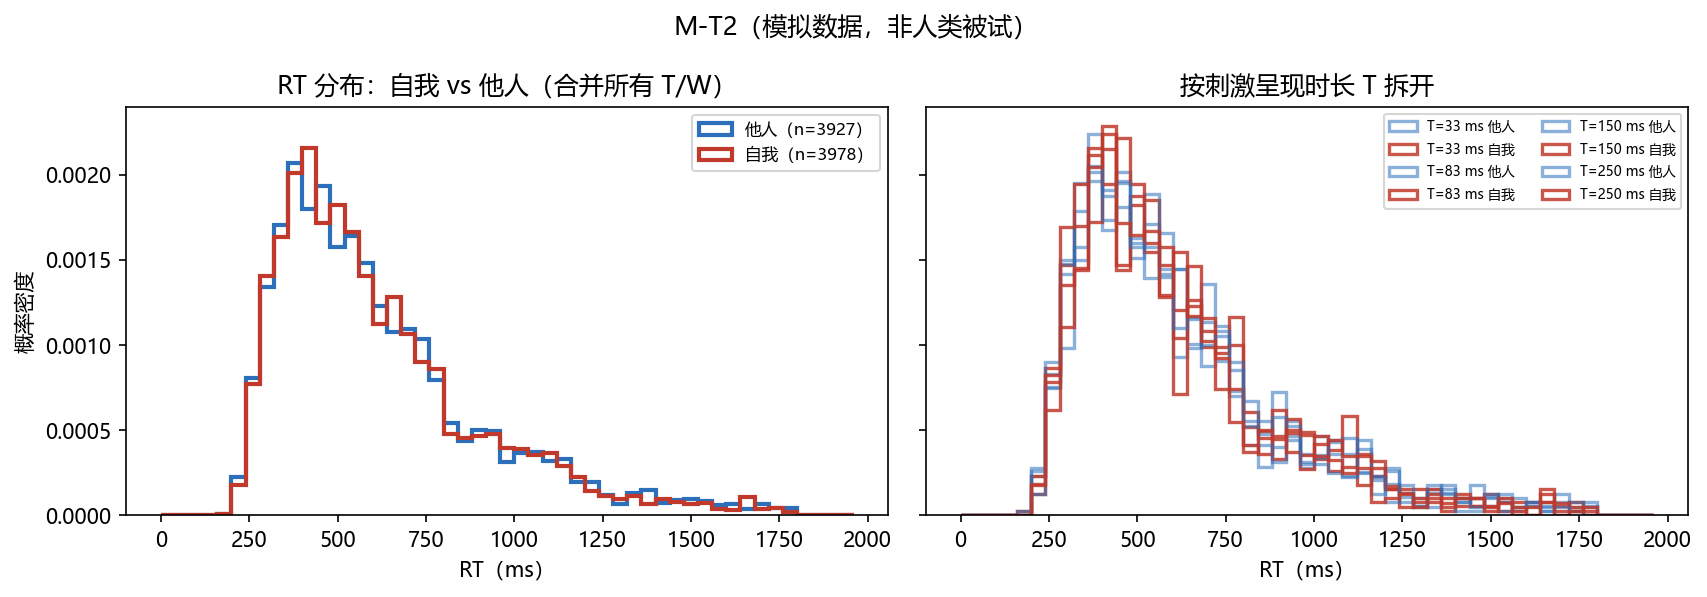

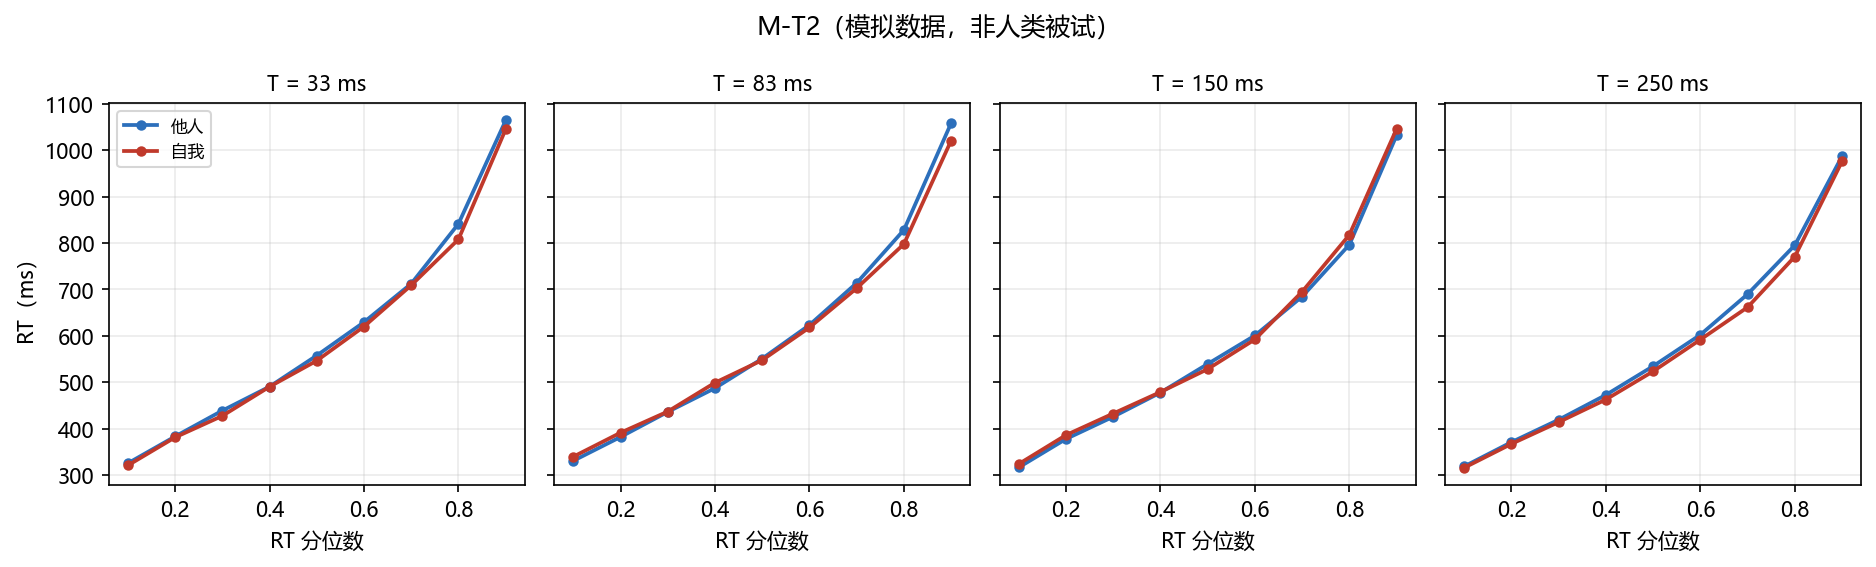

In [4]:

# 图 1 / 图 2：RT 分布与分位曲线
V.plot_rt_density(df, OUT / "figures" / "fig1_rt_density.png", title=f"{MODEL}（模拟数据，非人类被试）")
V.plot_rt_quantiles(df, OUT / "figures" / "fig2_rt_quantiles.png", title=f"{MODEL}（模拟数据，非人类被试）")
display(Image(filename=str(OUT / "figures" / "fig1_rt_density.png"), width=980))
display(Image(filename=str(OUT / "figures" / "fig2_rt_quantiles.png"), width=980))


### 图 3：正确率 / 遗漏率

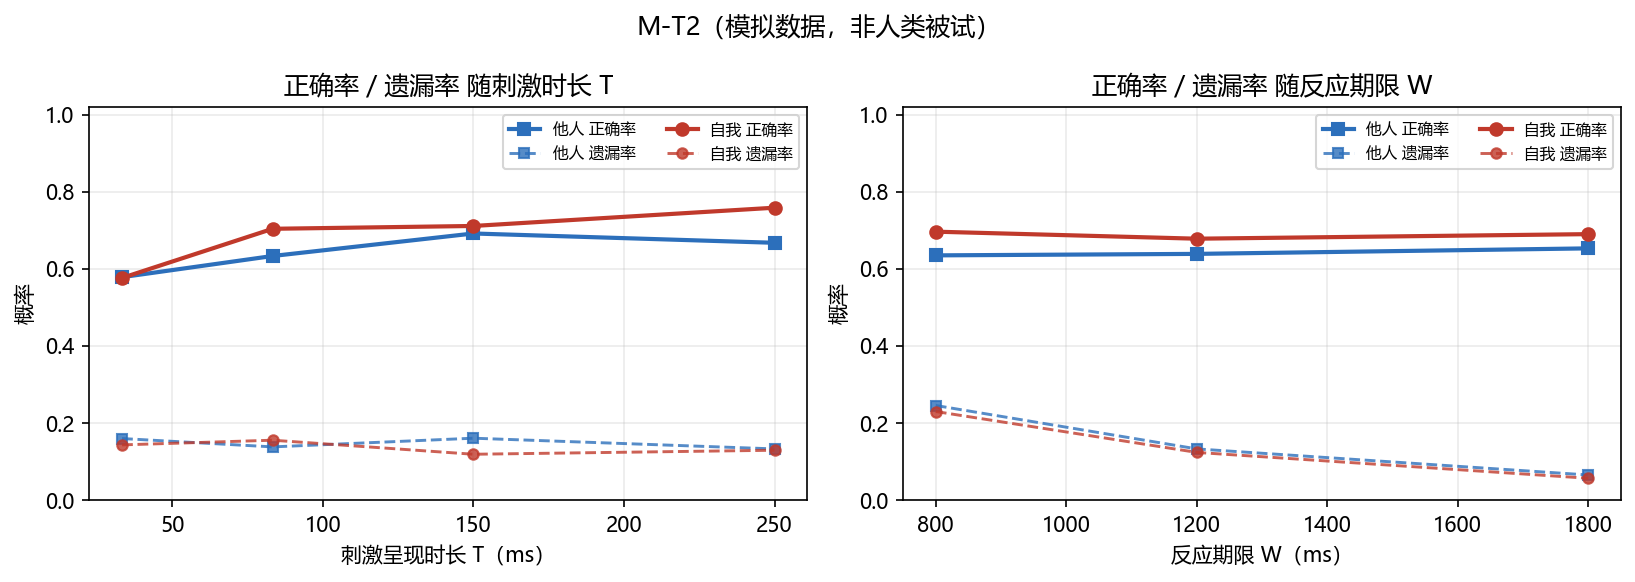

In [5]:

# 图 3：正确率 / 遗漏率 随 T 与 W——设计的两个操作变量有没有效果
V.plot_accuracy_omission(df, OUT / "figures" / "fig3_accuracy_omission.png",
                         title=f"{MODEL}（模拟数据，非人类被试）")
display(Image(filename=str(OUT / "figures" / "fig3_accuracy_omission.png"), width=980))


### 图 4：CRF（条件正确率函数）

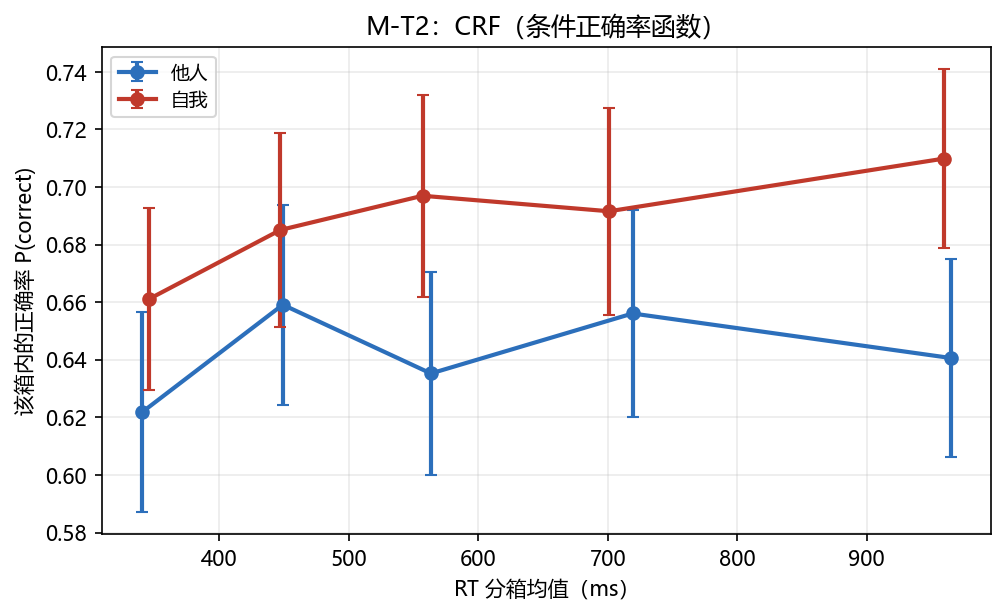

 is_self  bin   n  rt_mean_ms  p_correct    sd  n_subj    se  ci_lo  ci_hi
       0    1 834     340.303      0.622 0.245     192 0.018  0.587  0.656
       0    2 742     448.984      0.659 0.246     192 0.018  0.624  0.694
       0    3 758     563.378      0.635 0.249     192 0.018  0.600  0.670
       0    4 727     719.158      0.656 0.255     192 0.018  0.620  0.692
       0    5 866     964.724      0.641 0.244     192 0.018  0.606  0.675
       1    1 838     345.741      0.661 0.223     192 0.016  0.630  0.693
       1    2 755     447.065      0.685 0.238     192 0.017  0.651  0.719
       1    3 770     556.903      0.697 0.248     192 0.018  0.662  0.732
       1    4 741     701.012      0.692 0.254     192 0.018  0.656  0.728
       1    5 874     960.007      0.710 0.219     192 0.016  0.679  0.741


In [6]:

# 图 4：CRF（条件正确率函数）——按 RT 五分位分箱看正确率
# ⚠️ 分箱必须在 (T × W × 身份) 内部做，否则「长 RT」会与「低漂移条件」混在一起
agg = V.crf_table(df, n_bins=5)
V.plot_crf(df, OUT / "figures" / "fig4_crf.png", title=f"{MODEL}：CRF（条件正确率函数）")
display(Image(filename=str(OUT / "figures" / "fig4_crf.png"), width=760))
print(agg.round(3).to_string(index=False))


### 图 5：delta 图

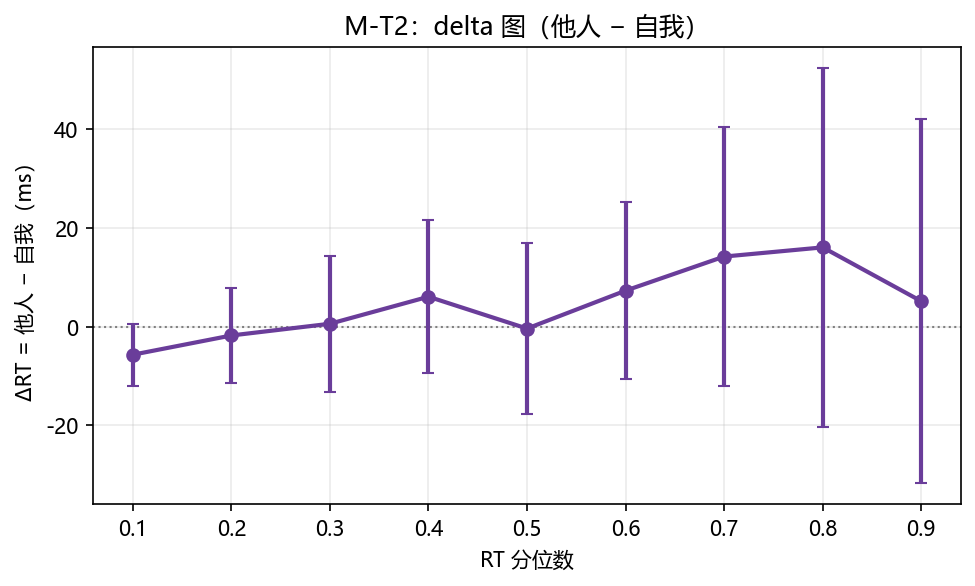

In [7]:

# 图 5：delta 图——他人 − 自我 在各 RT 分位上的差（每个点一名被试，误差条 = 95% CI）
V.plot_delta(df, OUT / "figures" / "fig5_delta.png", title=f"{MODEL}：delta 图（他人 − 自我）")
display(Image(filename=str(OUT / "figures" / "fig5_delta.png"), width=760))


### 图 6：机制图

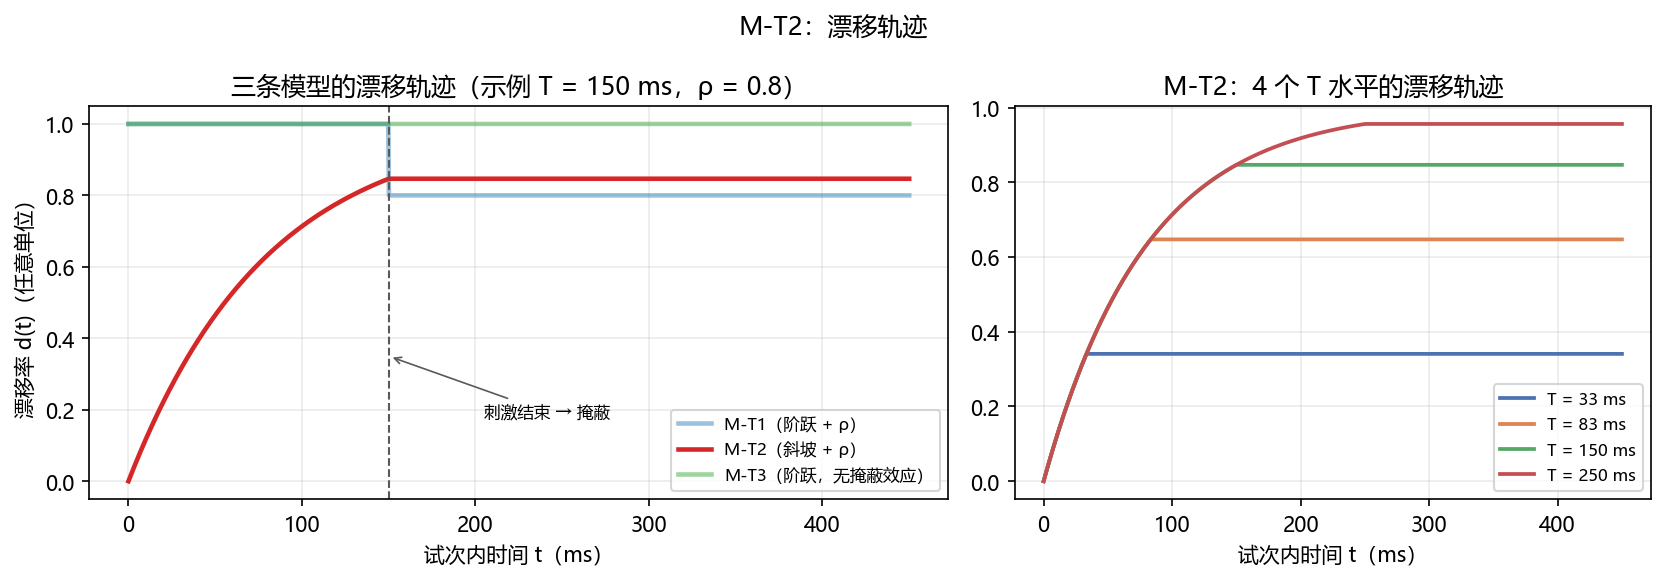

In [8]:

# 图 6：机制图——漂移轨迹（这是三条模型唯一的差别）
V.plot_mechanism(OUT / "figures" / "fig6_mechanism.png", MODEL,
                 rho=meta["rho"], tau_ramp=meta.get("tau_ramp") or 0.08,
                 title=f"{MODEL}：漂移轨迹")
display(Image(filename=str(OUT / "figures" / "fig6_mechanism.png"), width=1040))


## 4. 自检与产物

In [9]:

# 自检：这套数据「像不像人、有没有效应方向」
d = df[df.omission == 0]
acc = d.correct.mean()
om = df.omission.mean()
rt_med = d.rt_ms.median()
acc_by_T = d.groupby("T_ms").correct.mean()
self_acc = d[d.is_self == 1].correct.mean()
other_acc = d[d.is_self == 0].correct.mean()

checks = [
    ("正确率在 0.50–0.95", 0.50 <= acc <= 0.95, f"{acc:.3f}"),
    ("遗漏率在 0.02–0.45", 0.02 <= om <= 0.45, f"{om:.3f}"),
    ("RT 中位在 300–1200 ms", 300 <= rt_med <= 1200, f"{rt_med:.0f} ms"),
    ("T 越长越准（末端 > 首端）", acc_by_T.iloc[-1] > acc_by_T.iloc[0],
     f"{acc_by_T.iloc[0]:.3f} → {acc_by_T.iloc[-1]:.3f}"),
    ("自我比他人准", self_acc > other_acc, f"{self_acc:.3f} vs {other_acc:.3f}"),
]
for name, ok, val in checks:
    print(f"{'✅' if ok else '❌'} {name:28s} {val}")
print()
print("全部通过" if all(c[1] for c in checks) else "有项目未通过——先别急着用这套数据")


✅ 正确率在 0.50–0.95               0.666
✅ 遗漏率在 0.02–0.45               0.142
✅ RT 中位在 300–1200 ms           541 ms
✅ T 越长越准（末端 > 首端）              0.577 → 0.713
✅ 自我比他人准                       0.688 vs 0.643

全部通过


In [10]:

# 产物清单
print(f"{'文件':34s} {'大小':>10s}")
for p in sorted(OUT.rglob("*")):
    if p.is_file():
        print(f"{str(p.relative_to(OUT)):34s} {p.stat().st_size / 1024:9.1f} KB")


文件                                         大小
cells.csv                                5.3 KB
crf_table.csv                            1.3 KB
figures\fig1_rt_density.png             88.4 KB
figures\fig2_rt_quantiles.png           93.4 KB
figures\fig3_accuracy_omission.png      92.3 KB
figures\fig4_crf.png                    65.2 KB
figures\fig5_delta.png                  38.9 KB
figures\fig6_mechanism.png              95.9 KB
meta.json                                0.7 KB
subjects.csv                             1.6 KB
trials_long.csv                        748.9 KB
